Набор данных:

уникальный ключ состоит из: date, platform, publisher и group name.
Platform - платформа, на которой отображена страница (мобильная, десктопная)
Group name - группа A/B (органический элемент первый/органический последний)
Page views - количество веб-страниц, на которых был запущен тест
Visible page views - количество просмотров страниц, где пользователь увидел ленту
news_portal Sessions - все просмотры страниц пользователя на конкретном издателе в течение двух часов
Paid clicks - клики по платным элементам (реклама)
Organic clicks - клики по элементам с контентом издателя



Количество просмотров за сессию: среднее количество страниц, просмотренных за сеанс пользователем
RPM (Revenue per mille): доход на 1 000 просмотров страниц
RPS (Revenue per session): доход на 1 000 сессий
Paid/Organic CTR (Click-Through Rate): коэффициент переходов (CTR) по платным/органическим кликам относительно числа просмотров страниц
Visibility Rate: количество видимых просмотров страниц относительно общего числа просмотров страниц


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns

df_main = pd.read_excel('./data/news_portal_ab_test.xlsx')

df_main.head(5)

,date,publisher_id,platform,group_name,pageviews,visible_pageviews,sessions,revenue,sponsord_clicks,organic_clicks
0,2019-03-01,101,Desktop,A,16580,5418,12684,34.5201,300,849
1,2019-03-01,101,Desktop,B,16191,4906,12717,32.9211,268,555
2,2019-03-01,106,Desktop,A,16227,11395,11750,20.1620,601,2425
3,2019-03-01,106,Desktop,B,15060,10369,11967,19.7429,663,1194
4,2019-03-01,106,Mobile,A,30494,7715,22843,82.9329,456,1600


Компания провела эксперимент:
Группа A (контроль): сверху 1 органический, снизу 4 платных.
Группа B (тест): сверху 4 платных, снизу 1 органический.
Вопрос бизнеса: если поставить платные наверх, мы заработаем больше или потеряем на том, что люди меньше читают сайт?

Выбросы? Дубли?

а,б(мобильный/десктоп) - ср, медиана по выручке, % платных\бесплатных кликов (смотрим на visible_pageviews, sessions? что показывают?)






<Axes: xlabel='date', ylabel='spons_cr'>

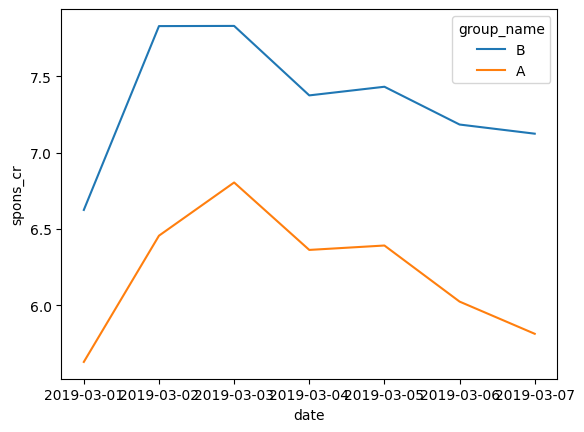

In [ ]:
test_df = df_main.copy()

# 1 false - подсчет среднего от процентов, round() до агрегации, 

test_df = test_df.drop(columns=['revenue','sessions'])
test_df['visible_rate'] = round((test_df['visible_pageviews'] / test_df['pageviews']) *100, 2)
test_df['spons_cr'] = round((test_df['sponsord_clicks'] / test_df['visible_pageviews']) *100, 2)

grouped_1_df = test_df.groupby(['date', 'group_name']).agg({
    'visible_rate' : 'mean',
    'spons_cr' : 'mean',
}).reset_index().sort_values('spons_cr', ascending=False)
grouped_1_df
sns.lineplot(data=grouped_1_df, x='date', y='spons_cr', hue='group_name')





# daily = test_df.groupby(['date', 'group_name'])[['sponsord_clicks', 'pageviews']].sum().reset_index()
# daily['paid_ctr'] = daily['sponsord_clicks'] / daily['pageviews'] * 100

# sns.lineplot(data=daily, x='date', y='paid_ctr', hue='group_name')




In [ ]:
# 2


class Data_check:
    is_na = None
    is_not_duplicate = None
    pairs = None
    main_df:pd.DataFrame = None

    def __init__(self, main_df, df_key=None):
        self.main_df = main_df.copy()
        self.check_na()
        self.check_dublicate(df_key)
        self.pairs_check(df_key)

    def __str__(self):
        result = f'Пробелы в данных - {bool(self.is_na)}\
            \nДубликаты - {bool(self.is_not_duplicate)}\
            \nПарность групп - {bool(self.pairs)}\n'

        base_info = f"Платформы - {self.main_df['platform'].unique()}\nГруппы - {self.main_df['group_name'].unique()}\
            \nДаты - c {self.main_df['date'].min()} по {self.main_df['date'].max()} \nВсего - {self.main_df['date'].nunique()}\n\n"

        
        return base_info + result 


    def check_na(self):
        na_df = self.main_df.isna().sum().reset_index()
        self.is_na = na_df[na_df[0].notnull()].empty

    def check_dublicate(self, df_key=None):
        self.is_not_duplicate = self.main_df.duplicated().sum() or self.main_df.duplicated(subset=df_key).sum()

    def pairs_check(self, df_key=None):
        if df_key:
            df_key.remove('group_name')
        pairs_df = self.main_df.groupby(df_key)['group_name'].nunique().reset_index()
        self.pairs = pairs_df[pairs_df['group_name'] == 1].empty
        if not self.pairs:
            print('связок без пары A/B:', (pairs_df['group_name'] < 2).sum())

    def SRM_check(self):
        # Добавить просто srm чек или нет? 
        pass
        






# fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(16, 6))
# plot = sns.barplot(data=ab_by_platform, y='rpm', x='group_name', hue='platform', ax=ax1)
# plot.set(xlabel = 'Группа', ylabel = 'RPM')
# plot.set_ylim(0, 5)

# plot = sns.barplot(data=ab_by_platform, y='rps', x='group_name', hue='platform', ax=ax2)
# plot.set(xlabel = 'Группа', ylabel = 'PRS')
# plot.set_ylim(0, 5)

# plot = sns.barplot(data=ab_by_platform, y='org_ctr', x='group_name', hue='platform', ax=ax3)
# # plot.set(xlabel = 'Группа', ylabel = 'PRS')
# # plot.set_ylim(0, 5)

# plot = sns.barplot(data=ab_by_platform, y='pv_per_sess', x='group_name', hue='platform', ax=ax4)
# plt.tight_layout()
